# TB1 JST: Klasifikasi Breast Cancer Wisconsin (Diagnostic)
## Perceptron dan ADALINE menggunakan NumPy

Kelompok **XX**.


**Kasus:** klasifikasi diagnosis sampel jinak (`B=-1`) dan ganas (`M=+1`, kelas positif) dari karakteristik inti sel. Eksperimen memakai empat fitur yang ditetapkan sebelum evaluasi: `radius_mean`, `texture_mean`, `smoothness_mean`, `concavity_mean`.

Isi data.csv: 569 observasi, 33 kolom, diagnosis B=357 dan M=212. Terdapat 30 pengukuran numerik, satu ID, satu target, dan `Unnamed: 32` yang kosong seluruhnya. Tidak ada nilai kosong pada 30 pengukuran atau diagnosis, tidak ada duplikasi baris maupun duplikasi 30 fitur. Kolom ID dan kolom kosong tidak menjadi fitur. Semua baris dipertahankan, tanpa imputasi/oversampling/penghapusan outlier.

`dataset.csv` berisi empat fitur pada skala asli, `diagnosis`, dan `label`. Dua kolom target tidak masuk X. Pemilihan empat fitur menggambarkan ukuran, tekstur dan bentuk. Tidak sekaligus memakai radius/perimeter/area yang semuanya terkait ukuran. Subset ini tidak diklaim optimal atau dipilih dari test.

- `radius_mean`: Rerata jarak dari pusat inti sel ke titik pada perimeter. Mewakili ukuran.
- `texture_mean`: Rerata karakteristik tekstur, dihitung dari simpangan baku intensitas keabuan.
- `smoothness_mean`: Rerata variasi lokal panjang radius. Mewakili kehalusan batas inti sel.
- `concavity_mean`: Rerata tingkat cekungan bagian kontur inti sel.

**scikit-learn** digunakan hanya untuk split, scaler dan metrik. Implementasi fit kedua model memakai NumPy.

## 3. Rancangan terkunci sebelum evaluasi uji

In [21]:
from pathlib import Path
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score

# Empat fitur ditetapkan terlebih dahulu sebelum evaluasi, tanpa pencarian memakai data uji.
FEATURES = ["radius_mean", "texture_mean", "smoothness_mean", "concavity_mean"]
SEED = 42
EPOCHS = 50
# Daftar ini juga ditetapkan sebelum training dan evaluasi data uji.
CONFIGS = [
    {"id": f"{prefix}-S-{str(eta).replace('.', '')}", "model": name, "eta": eta, "standardized": True}
    for name, prefix in [("Perceptron", "P"), ("ADALINE", "A")]
    for eta in [0.001, 0.01, 0.1]
] + [
    {"id": "P-R-001", "model": "Perceptron", "eta": 0.01, "standardized": False},
    {"id": "A-R-001", "model": "ADALINE", "eta": 0.01, "standardized": False},
]


BASE = Path.cwd()
assert (BASE / "dataset.csv").is_file()
display(pd.DataFrame(CONFIGS))
print("Python:", platform.python_version(), "seed:", SEED)

import base64

def display_png(path):
    encoded = base64.b64encode(Path(path).read_bytes()).decode("ascii")
    try:
        display({"image/png": encoded}, raw=True)
    except TypeError:
        display({"image/png": encoded})


,id,model,eta,standardized
0,P-S-0001,Perceptron,0.001,True
1,P-S-001,Perceptron,0.010,True
2,P-S-01,Perceptron,0.100,True
3,A-S-0001,ADALINE,0.001,True
4,A-S-001,ADALINE,0.010,True
5,A-S-01,ADALINE,0.100,True
6,P-R-001,Perceptron,0.010,False
7,A-R-001,ADALINE,0.010,False


Python: 3.13.15 seed: 42


## 4. Neuron dan implementasi Perceptron
Semua model dimulai w=0 dan b=0, urutan train tetap, 50 epoch tanpa early stopping akibat nol kesalahan.

In [22]:
def validate_xy(X, y):
    X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=int)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
        raise ValueError("X harus matriks n x p dan y vektor sepanjang n > 0.")
    if not np.isfinite(X).all() or not np.isin(y, [-1, 1]).all():
        raise ValueError("Fitur harus finite dan label harus -1/+1.")
    return X, y

def predict_linear(X, w, b):
    """Ambang nol, termasuk tie z=0 yang menghasilkan +1."""
    return np.where(np.asarray(X) @ w + b >= 0, 1, -1)

class PerceptronNumPy:
    def __init__(self, eta=0.01, epochs=50):
        if not np.isfinite(eta) or eta <= 0 or epochs < 1:
            raise ValueError("eta harus positif finite dan epochs >= 1.")
        self.eta, self.epochs = eta, epochs

    def fit(self, X, y):
        X, y = validate_xy(X, y)
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.history_, self.snapshots_, self.manual_trace_ = [], {}, []
        self.stop_epoch_ = None
        for epoch in range(1, self.epochs + 1):
            updates = 0
            # Urutan hasil split digunakan tetap pada setiap epoch.
            for position, (xi, target) in enumerate(zip(X, y)):
                z = float(xi @ self.w_ + self.b_)
                prediction = 1 if z >= 0 else -1
                delta = self.eta * (target - prediction)
                old_w, old_b = self.w_.copy(), self.b_
                self.w_ = self.w_ + delta * xi
                self.b_ = self.b_ + delta
                if delta != 0:
                    updates += 1
                    if len(self.manual_trace_) < 2:
                        self.manual_trace_.append({
                            "epoch": epoch, "position": position, "x": xi.tolist(),
                            "y": int(target), "z": z, "prediction": prediction,
                            "delta": float(delta), "w_before": old_w.tolist(),
                            "b_before": float(old_b), "w_after": self.w_.tolist(),
                            "b_after": float(self.b_),
                        })
            errors = int(np.count_nonzero(self.predict(X) != y))
            self.history_.append({"epoch": epoch, "updates": updates,
                                  "train_errors": errors, "train_accuracy": 1-errors/len(y)})
            self.snapshots_[epoch] = (self.w_.copy(), float(self.b_))
        return self

    def predict(self, X):
        return predict_linear(X, self.w_, self.b_)

## 5. ADALINE (dengan batch Delta Rule)

$$e=y-(Xw+b),\quad J=\frac{1}{2n}\sum_i e_i^2,\quad MSE=2J$$
$$w\leftarrow w+\eta X^Te/n,\quad b\leftarrow b+\eta\operatorname{mean}(e)$$

Semua komponen gradient satu iterasi memakai bobot lama yang sama. Error berasal dari linear output, bukan label hasil threshold. J dicatat **sesudah** pembaruan. Threshold hanya dipakai saat prediksi/metrik.

In [23]:
class AdalineNumPy:
    def __init__(self, eta=0.01, epochs=50):
        if not np.isfinite(eta) or eta <= 0 or epochs < 1:
            raise ValueError("eta harus positif finite dan epochs >= 1.")
        self.eta, self.epochs = eta, epochs

    def fit(self, X, y):
        X, y = validate_xy(X, y)
        n = len(y)
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.history_, self.snapshots_, self.manual_trace_ = [], {}, []
        self.stop_epoch_ = None
        self.initial_loss_ = 0.5 * float(np.mean(y.astype(float)**2))
        for epoch in range(1, self.epochs + 1):
            # Error LINEAR. Prediksi hasil threshold tidak masuk gradient.
            with np.errstate(over="ignore", invalid="ignore"):
                z = X @ self.w_ + self.b_
                e = y - z
                direction_w, direction_b = X.T @ e / n, float(np.mean(e))
                new_w = self.w_ + self.eta * direction_w
                new_b = self.b_ + self.eta * direction_b
                new_e = y - (X @ new_w + new_b)
                J = 0.5 * float(np.mean(new_e**2))
            if not (np.isfinite(new_w).all() and np.isfinite(new_b) and np.isfinite(J)):
                self.stop_epoch_ = epoch
                break
            if epoch <= 2:
                self.manual_trace_.append({
                    "epoch": epoch, "n": n, "w_before": self.w_.tolist(),
                    "b_before": float(self.b_), "sum_Xe": (direction_w*n).tolist(),
                    "mean_e": direction_b, "direction_w": direction_w.tolist(),
                    "w_after": new_w.tolist(), "b_after": float(new_b), "J_after": J,
                })
            self.w_, self.b_ = new_w, float(new_b)
            errors = int(np.count_nonzero(self.predict(X) != y))
            self.history_.append({"epoch": epoch, "J": J, "MSE": 2*J,
                                  "train_errors": errors, "train_accuracy": 1-errors/n})
            self.snapshots_[epoch] = (self.w_.copy(), self.b_)
        return self

    def predict(self, X):
        return predict_linear(X, self.w_, self.b_)

## 6. Audit, split 80:20, dan standardisasi train-only

In [24]:
def prepare_data(base):
    base = Path(base)
    raw = pd.read_csv(base / "data/raw_breast_cancer.csv")
    expected = raw[FEATURES + ["diagnosis"]].copy()
    expected["label"] = expected["diagnosis"].map({"B": -1, "M": 1})
    df = pd.read_csv(base / "dataset.csv")
    pd.testing.assert_frame_equal(df, expected)
    assert not df.isna().any().any() and not df.duplicated().any()
    assert len(df) == 569 and set(df["diagnosis"]) == {"B", "M"}
    assert df.groupby(FEATURES)["label"].nunique().max() == 1
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices, test_size=0.2, random_state=SEED, stratify=df["label"].to_numpy())
    X, y = df[FEATURES].to_numpy(float), df["label"].to_numpy(int)
    scaler = StandardScaler().fit(X[train_idx])
    arrays = {
        True: (scaler.transform(X[train_idx]), scaler.transform(X[test_idx])),
        False: (X[train_idx].copy(), X[test_idx].copy()),
    }
    assert set(train_idx).isdisjoint(test_idx)
    assert set(map(tuple, X[train_idx])).isdisjoint(set(map(tuple, X[test_idx])))
    return df, train_idx, test_idx, arrays, y[train_idx], y[test_idx], scaler

def metrics(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[-1, 1]).ravel()
    return {"accuracy": float(accuracy_score(y, pred)),
            "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
            "precision": float(precision_score(y, pred, pos_label=1, zero_division=0)),
            "recall": float(recall_score(y, pred, pos_label=1, zero_division=0)),
            "f1": float(f1_score(y, pred, pos_label=1, zero_division=0)),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

In [25]:
from pathlib import Path
import shutil

BASE = Path("/content")
(BASE / "data").mkdir(exist_ok=True)
shutil.copy2(BASE / "raw_breast_cancer.csv",
             BASE / "data" / "raw_breast_cancer.csv")

PosixPath('/content/data/raw_breast_cancer.csv')

In [26]:
df, tr, te, arrays, yt, ye, scaler = prepare_data(BASE)
raw = pd.read_csv(BASE / "data/raw_breast_cancer.csv")
print("Raw:", raw.shape, "CSV eksperimen:", df.shape)
print("Missing raw:", raw.isna().sum()[raw.isna().sum()>0].to_dict())
print("Duplikasi baris raw:", raw.duplicated().sum())
display(df.head())
display(pd.crosstab(df.diagnosis, df.label))
print("Train:", len(tr), "Test:", len(te))
display(pd.DataFrame({"feature": FEATURES, "train_mean": scaler.mean_, "train_std_ddof0": scaler.scale_}))
print("Target train:", dict(zip(*np.unique(yt, return_counts=True))))
print("Target test:", dict(zip(*np.unique(ye, return_counts=True))))


Raw: (569, 33) CSV eksperimen: (569, 6)
Missing raw: {'Unnamed: 32': 569}
Duplikasi baris raw: 0


,radius_mean,texture_mean,smoothness_mean,concavity_mean,diagnosis,label
0,17.99,10.38,0.11840,0.3001,M,1
1,20.57,17.77,0.08474,0.0869,M,1
2,19.69,21.25,0.10960,0.1974,M,1
3,11.42,20.38,0.14250,0.2414,M,1
4,20.29,14.34,0.10030,0.1980,M,1


label,-1,1
diagnosis,,
B,357,0
M,0,212


Train: 455 Test: 114


,feature,train_mean,train_std_ddof0
0,radius_mean,14.166077,3.575146
1,texture_mean,19.417692,4.285935
2,smoothness_mean,0.095993,0.014294
3,concavity_mean,0.089184,0.081608


Target train: {np.int64(-1): np.int64(285), np.int64(1): np.int64(170)}
Target test: {np.int64(-1): np.int64(72), np.int64(1): np.int64(42)}


`train_test_split(test_size=0.2, random_state=42, stratify=y)` menghasilkan 455 train dan 114 test. Mean/std (ddof=0) berasal hanya dari train. Enam konfigurasi memakai data standar. Dua kontrol memakai skala asli, eta=0.01, 50 epoch. Tidak ada seleksi/tuning lewat test. Fokus pembahasan eta=0.01 ditentukan sebelum evaluasi. Checkpoint 10/30/50 hanya merangkum riwayat latih yang sama.

## 7. Eksekusi delapan konfigurasi dan ekspor hasil

In [27]:
def run_all(base, make_figures=True):
    base = Path(base)
    for folder in ["results", "figures"]:
        (base/folder).mkdir(exist_ok=True)
    df, train_idx, test_idx, arrays, y_train, y_test, scaler = prepare_data(base)
    # Tahap 1: latih kedelapan konfigurasi TANPA evaluasi data uji.
    models = {}
    for cfg in CONFIGS:
        cls = PerceptronNumPy if cfg["model"] == "Perceptron" else AdalineNumPy
        models[cfg["id"]] = cls(cfg["eta"], EPOCHS).fit(arrays[cfg["standardized"]][0], y_train)
    # Tahap 2: satu pelaporan uji akhir untuk tiap konfigurasi yang telah dikunci.
    rows, history, checkpoints, weights, predictions = [], [], [], [], []
    for cfg in CONFIGS:
        model = models[cfg["id"]]
        Xtr, Xte = arrays[cfg["standardized"]]
        mt, me = metrics(y_train, model.predict(Xtr)), metrics(y_test, model.predict(Xte))
        last = model.history_[-1]
        row = dict(cfg, requested_epochs=EPOCHS, completed_epochs=len(model.history_),
                   nonfinite_epoch=model.stop_epoch_, train_accuracy=mt["accuracy"],
                   train_errors=last["train_errors"], test_accuracy=me["accuracy"],
                   test_balanced_accuracy=me["balanced_accuracy"], test_precision=me["precision"],
                   test_recall=me["recall"], test_f1=me["f1"],
                   tn=me["tn"], fp=me["fp"], fn=me["fn"], tp=me["tp"],
                   final_updates=last.get("updates"), final_J=last.get("J"), final_MSE=last.get("MSE"))
        rows.append(row)
        history.extend(dict(config=cfg["id"], **h) for h in model.history_)
        checkpoints.extend(dict(config=cfg["id"], **h) for h in model.history_ if h["epoch"] in [10,30,50])
        wr = dict(config=cfg["id"], **dict(zip(FEATURES,model.w_.tolist())), bias=model.b_)
        weights.append(wr)
        for idx, actual, pred, z in zip(test_idx, y_test, model.predict(Xte), Xte@model.w_+model.b_):
            predictions.append({"config":cfg["id"], "row_id":int(idx), "actual":int(actual), "prediction":int(pred), "z":float(z)})
    tables = {"metrics":pd.DataFrame(rows),"history":pd.DataFrame(history),
              "checkpoints":pd.DataFrame(checkpoints),"weights":pd.DataFrame(weights),
              "predictions_test":pd.DataFrame(predictions)}
    for name, table in tables.items():
        table.to_csv(base/f"results/{name}.csv",index=False)
    split = pd.DataFrame({"row_id":np.r_[train_idx,test_idx],
                          "split":["train"]*len(train_idx)+["test"]*len(test_idx),
                          "order":np.r_[np.arange(len(train_idx)),np.arange(len(test_idx))]})
    split.to_csv(base/"results/split.csv", index=False)
    pd.DataFrame({"feature":FEATURES,"train_mean":scaler.mean_,"train_std_ddof0":scaler.scale_}).to_csv(base/"results/scaler.csv",index=False)
    stability = {}
    for scaled in [True,False]:
        Xtr = arrays[scaled][0]
        augmented = np.column_stack([Xtr,np.ones(len(Xtr))])
        eigmax = float(np.linalg.eigvalsh(augmented.T@augmented/len(Xtr)).max())
        stability[str(scaled)] = {"lambda_max":eigmax,"eta_upper_bound":2/eigmax}
    p = models["P-S-001"]
    manual = {"eta":0.01,"feature_order":FEATURES,"perceptron":p.manual_trace_,
              "adaline":models["A-S-001"].manual_trace_}
    for trace in manual["perceptron"]:
        trace["dataset_row_id"] = int(train_idx[trace["position"]])
    (base/"results/manual.json").write_text(json.dumps(manual,indent=2),encoding="utf-8")
    summary = {"seed":SEED,"epochs":EPOCHS,"train_n":len(train_idx),"test_n":len(test_idx),
               "train_counts":{str(k):int(v) for k,v in zip(*np.unique(y_train,return_counts=True))},
               "test_counts":{str(k):int(v) for k,v in zip(*np.unique(y_test,return_counts=True))},
               "stability":stability,"python":platform.python_version(),
               "dataset_sha256":hashlib.sha256((base/"dataset.csv").read_bytes()).hexdigest(),
               "features":FEATURES,"label_map":{"B":-1,"M":1},
               "raw_sha256":hashlib.sha256((base/"data/raw_breast_cancer.csv").read_bytes()).hexdigest(),
               "selection":"Tidak ada seleksi model/parameter. Empat fitur dan fokus eta=0.01 ditetapkan sebelum evaluasi uji."}
    (base/"results/summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
    if make_figures:
        plot_results(base,df,train_idx,test_idx,arrays,y_train,y_test,models,tables)
    return tables, models, summary

def plot_results(base,df,train_idx,test_idx,arrays,y_train,y_test,models,tables):
    plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":10,
                         "axes.spines.top":False,"axes.spines.right":False,
                         "figure.dpi":120,"savefig.dpi":180})
    colors = ["#117C83", "#E09037", "#6159A5"]
    def save(fig,name):
        fig.savefig(base/f"figures/{name}.png",bbox_inches="tight",facecolor="white")
        plt.close(fig)
    # Hanya data latih digunakan untuk eksplorasi pola.
    fig,axs=plt.subplots(1,2,figsize=(10,3.5))
    for ax,(a,b) in zip(axs,[(0,1),(0,2)]):
        for label,col in [(-1,colors[0]),(1,colors[1])]:
            part=df.iloc[train_idx].loc[lambda t:t.label==label]
            ax.scatter(part[FEATURES[a]],part[FEATURES[b]],s=11,alpha=.55,c=col,label=f"kelas {label:+d}")
        ax.set(xlabel=FEATURES[a],ylabel=FEATURES[b]);ax.legend(fontsize=9)
    fig.suptitle("Proyeksi data latih: dua pasangan dari empat fitur")
    fig.tight_layout();save(fig,"data_train")
    fig,axs=plt.subplots(1,2,figsize=(10,3.4))
    for eta,col in zip([.001,.01,.1],colors):
        key=str(eta).replace('.','')
        ph=pd.DataFrame(models[f"P-S-{key}"].history_)
        ah=pd.DataFrame(models[f"A-S-{key}"].history_)
        axs[0].plot(ph.epoch,ph.updates,color=col,label=f"eta={eta}",alpha=.8,linestyle={.001:'-',.01:'--',.1:':'}[eta])
        axs[1].plot(ah.epoch,ah.J,color=col,label=f"eta={eta}")
    axs[0].set(title="Perceptron",xlabel="Epoch",ylabel="Jumlah pembaruan salah klasifikasi")
    axs[1].set(title="ADALINE",xlabel="Epoch",ylabel="J setelah pembaruan batch")
    axs[1].set_yscale("log")
    for ax in axs: ax.legend();ax.grid(alpha=.15)
    fig.tight_layout();save(fig,"learning_scaled")
    fig,axs=plt.subplots(1,2,figsize=(10,3.4))
    for tag,label,col in [("S","Standardisasi",colors[0]),("R","Tanpa standardisasi",colors[1])]:
        ph=pd.DataFrame(models[f"P-{tag}-001"].history_)
        ah=pd.DataFrame(models[f"A-{tag}-001"].history_)
        axs[0].plot(ph.epoch,ph.updates,label=label,color=col)
        axs[1].plot(ah.epoch,ah.J,label=label,color=col)
    axs[0].set(title="Perceptron, eta=0.01",xlabel="Epoch",ylabel="Jumlah pembaruan")
    axs[1].set(title="ADALINE, eta=0.01",xlabel="Epoch",ylabel="J setelah pembaruan batch")
    axs[1].set_yscale("log")
    for ax in axs: ax.legend();ax.grid(alpha=.15)
    fig.tight_layout();save(fig,"scaling_comparison")
    fig,axs=plt.subplots(2,4,figsize=(11,5.5))
    for ax,row in zip(axs.flat,tables['metrics'].to_dict('records')):
        cm=np.array([[row['tn'],row['fp']],[row['fn'],row['tp']]])
        ax.imshow(cm,cmap='Blues',vmin=0,vmax=max(np.bincount((y_test+1)//2)))
        for i in range(2):
            for j in range(2):ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=12,color='white' if cm[i,j]>max(np.bincount((y_test+1)//2))/2 else '#163044')
        ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['-1','+1'],yticklabels=['-1','+1'],title=row['id'],xlabel='Prediksi',ylabel='Aktual')
    fig.tight_layout();save(fig,"confusion_all")
    fig,axs=plt.subplots(1,2,figsize=(10,3.5))
    xx,yy=np.meshgrid(np.linspace(-3,3,180),np.linspace(-3,3,180))
    grid=np.column_stack([xx.ravel(),yy.ravel(),np.zeros(xx.size),np.zeros(xx.size)])
    for ax,cid in zip(axs,["P-S-001","A-S-001"]):
        model=models[cid];zz=(grid@model.w_+model.b_).reshape(xx.shape)
        ax.contourf(xx,yy,np.where(zz>=0,1,-1),levels=[-2,0,2],colors=["#D3EEEA","#FCE6CA"])
        contour=ax.contour(xx,yy,zz,levels=[0],colors=['#173B4C'],linewidths=1.5)
        ax.clabel(contour,fmt={0:'z=0'});ax.set(title=cid,xlabel='radius_mean (standar)',ylabel='texture_mean (standar)')
    fig.suptitle("Irisan 4D: smoothness_mean=0 dan concavity_mean=0 (standar)")
    fig.tight_layout();save(fig,"boundary_slice")

In [28]:
tables, models, summary = run_all(BASE)
display(tables["metrics"])
print(json.dumps(summary, indent=2))


,id,model,eta,standardized,requested_epochs,completed_epochs,nonfinite_epoch,train_accuracy,train_errors,test_accuracy,...,test_precision,test_recall,test_f1,tn,fp,fn,tp,final_updates,final_J,final_MSE
0,P-S-0001,Perceptron,0.001,True,50,50,None,0.920879,36,0.894737,...,0.916667,0.785714,0.846154,69,3,9,33,43.0,NaN,NaN
1,P-S-001,Perceptron,0.010,True,50,50,None,0.920879,36,0.894737,...,0.916667,0.785714,0.846154,69,3,9,33,43.0,NaN,NaN
2,P-S-01,Perceptron,0.100,True,50,50,None,0.920879,36,0.894737,...,0.916667,0.785714,0.846154,69,3,9,33,43.0,NaN,NaN
3,A-S-0001,ADALINE,0.001,True,50,50,None,0.934066,30,0.938596,...,0.926829,0.904762,0.915663,69,3,4,38,NaN,4.411363e-01,8.822726e-01
4,A-S-001,ADALINE,0.010,True,50,50,None,0.934066,30,0.921053,...,0.923077,0.857143,0.888889,69,3,6,36,NaN,2.183923e-01,4.367845e-01
5,A-S-01,ADALINE,0.100,True,50,50,None,0.925275,34,0.903509,...,0.969697,0.761905,0.853333,71,1,10,32,NaN,1.648936e-01,3.297873e-01
6,P-R-001,Perceptron,0.010,False,50,50,None,0.408791,269,0.394737,...,0.378378,1.000000,0.549020,3,69,0,42,116.0,NaN,NaN
7,A-R-001,ADALINE,0.010,False,50,50,None,0.373626,285,0.368421,...,0.368421,1.000000,0.538462,0,72,0,42,NaN,6.658641e+67,1.331728e+68


{
  "seed": 42,
  "epochs": 50,
  "train_n": 455,
  "test_n": 114,
  "train_counts": {
    "-1": 285,
    "1": 170
  },
  "test_counts": {
    "-1": 72,
    "1": 42
  },
  "stability": {
    "True": {
      "lambda_max": 2.0958657818573685,
      "eta_upper_bound": 0.9542595796509394
    },
    "False": {
      "lambda_max": 599.8998110074975,
      "eta_upper_bound": 0.003333890031805668
    }
  },
  "python": "3.13.15",
  "dataset_sha256": "11629606eb03f536dd6128b728bdf0b52105a860bcc3b2cb2de5561020d11ef4",
  "features": [
    "radius_mean",
    "texture_mean",
    "smoothness_mean",
    "concavity_mean"
  ],
  "label_map": {
    "B": -1,
    "M": 1
  },
  "raw_sha256": "1425d9affa78ba8e53afc81d0ef8a19069ee10c4b21fe89b3cf514071b12ee33",
  "selection": "Tidak ada seleksi model/parameter. Empat fitur dan fokus eta=0.01 ditetapkan sebelum evaluasi uji."
}


## 8. Dua langkah manual Perceptron

P-S-001, eta=0.01. Contoh adalah dua pembaruan aktual pertama pada epoch 1, posisi train 1 dan 2 (indeks mulai 0). Sampel pertama pada posisi 0 berlabel +1 dan diprediksi +1 saat z=0, sehingga tidak memperbarui parameter. Urutan fitur mengikuti FEATURES. Lampiran laporan memuat perhitungan setiap komponen.

In [29]:
manual = json.loads((BASE / "results/manual.json").read_text())
for i, t in enumerate(manual["perceptron"], 1):
    print(f"\nLangkah {i}, row_id={t['dataset_row_id']}, posisi train={t['position']}")
    print("x =", np.array(t["x"]))
    print("w lama =", t["w_before"], "b lama =", t["b_before"])
    print(f"z = {t['z']:.9f}; y = {t['y']}; yhat = {t['prediction']}")
    print(f"Delta = {manual['eta']} * ({t['y']} - {t['prediction']}) = {t['delta']}")
    display(pd.DataFrame({"feature": FEATURES, "w_before": t["w_before"],
                          "delta_x": np.array(t["x"])*t["delta"], "w_after": t["w_after"]}))
    print("b baru =", t["b_after"])



Langkah 1, row_id=170, posisi train=1
x = [-0.51636409 -1.63971029  0.47621906 -0.60428117]
w lama = [0.0, 0.0, 0.0, 0.0] b lama = 0.0
z = 0.000000000; y = -1; yhat = 1
Delta = 0.01 * (-1 - 1) = -0.02


,feature,w_before,delta_x,w_after
0,radius_mean,0.0,0.010327,0.010327
1,texture_mean,0.0,0.032794,0.032794
2,smoothness_mean,0.0,-0.009524,-0.009524
3,concavity_mean,0.0,0.012086,0.012086


b baru = -0.02

Langkah 2, row_id=407, posisi train=2
x = [-0.36811839  0.45551496 -1.43297929 -0.34217507]
w lama = [0.010327281762275192, 0.03279420576422849, -0.009524381153266622, 0.012085623312018517] b lama = -0.02
z = 0.000649431; y = -1; yhat = 1
Delta = 0.01 * (-1 - 1) = -0.02


,feature,w_before,delta_x,w_after
0,radius_mean,0.010327,0.007362,0.017690
1,texture_mean,0.032794,-0.009110,0.023684
2,smoothness_mean,-0.009524,0.028660,0.019135
3,concavity_mean,0.012086,0.006844,0.018929


b baru = -0.04


## 9. Dua iterasi batch manual ADALINE

A-S-001, eta=0.01, n=455. Tabel memakai seluruh train yang sama dengan eksperimen, bukan batch ilustrasi lain. Pada batch 1: z=0, e=y, J awal=0.5. Batch 2 memakai bobot hasil batch 1. Hasil dan angka presisi penuh disimpan dalam `results/manual.json`.

In [30]:
for t in manual["adaline"]:
    print("\nBatch", t["epoch"], "n=", t["n"])
    print("w lama =", t["w_before"], "b lama =", t["b_before"])
    display(pd.DataFrame({"feature": FEATURES, "sum_Xe": t["sum_Xe"],
                          "XTe_div_n": t["direction_w"], "w_after": t["w_after"]}))
    print("mean(e) =", t["mean_e"], "b baru =", t["b_after"], "J sesudah update =", t["J_after"])



Batch 1 n= 455
w lama = [0.0, 0.0, 0.0, 0.0] b lama = 0.0


,feature,sum_Xe,XTe_div_n,w_after
0,radius_mean,320.555831,0.704518,0.007045
1,texture_mean,182.075685,0.400166,0.004002
2,smoothness_mean,171.065199,0.375967,0.003760
3,concavity_mean,300.978229,0.661491,0.006615


mean(e) = -0.25274725274725274 b baru = -0.0025274725274725273 J sesudah update = 0.48713887058842364

Batch 2 n= 455
w lama = [0.007045183095923422, 0.004001663398806307, 0.0037596747131037173, 0.00661490612429258] b lama = -0.0025274725274725273


,feature,sum_Xe,XTe_div_n,w_after
0,radius_mean,314.397487,0.690983,0.013955
1,texture_mean,178.348982,0.391976,0.007921
2,smoothness_mean,167.144064,0.367350,0.007433
3,concavity_mean,294.343640,0.646909,0.013084


mean(e) = -0.2502197802197802 b baru = -0.005029670329670329 J sesudah update = 0.4747936766839226


## 10. Kurva pembelajaran dan checkpoint latih

,config,epoch,updates,train_errors,train_accuracy,J,MSE
0,P-S-0001,10,42.0,34,0.925275,NaN,NaN
1,P-S-0001,30,42.0,42,0.907692,NaN,NaN
2,P-S-0001,50,43.0,36,0.920879,NaN,NaN
3,P-S-001,10,42.0,34,0.925275,NaN,NaN
4,P-S-001,30,42.0,42,0.907692,NaN,NaN
5,P-S-001,50,43.0,36,0.920879,NaN,NaN
6,P-S-01,10,42.0,34,0.925275,NaN,NaN
7,P-S-01,30,42.0,42,0.907692,NaN,NaN
8,P-S-01,50,43.0,36,0.920879,NaN,NaN
9,A-S-0001,10,NaN,31,0.931868,4.872543e-01,9.745086e-01


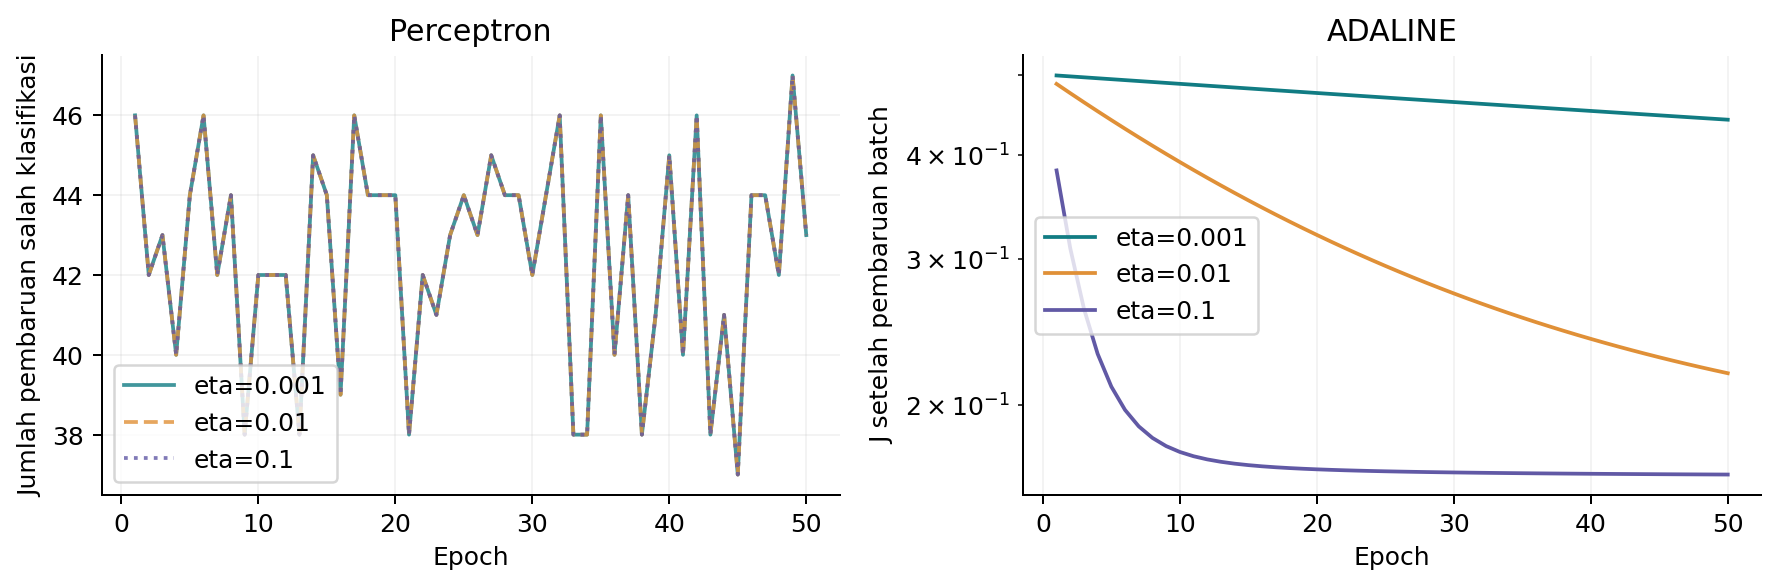

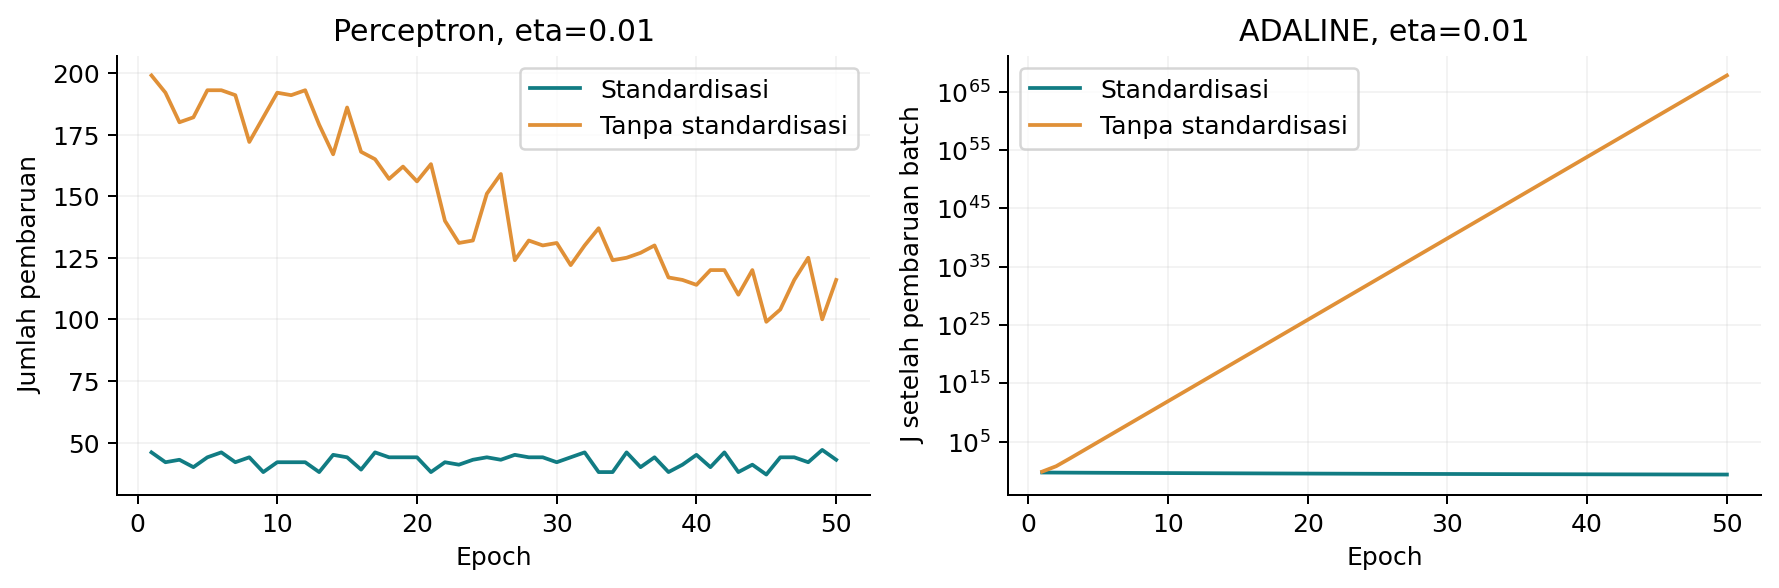

In [31]:
display(tables["checkpoints"])
import base64
display_png(BASE / "figures/learning_scaled.png")
display_png(BASE / "figures/scaling_comparison.png")


## 11. Confusion matrix dan parameter akhir

,id,tn,fp,fn,tp,test_precision,test_recall,test_f1,test_balanced_accuracy
0,P-S-0001,69,3,9,33,0.916667,0.785714,0.846154,0.872024
1,P-S-001,69,3,9,33,0.916667,0.785714,0.846154,0.872024
2,P-S-01,69,3,9,33,0.916667,0.785714,0.846154,0.872024
3,A-S-0001,69,3,4,38,0.926829,0.904762,0.915663,0.931548
4,A-S-001,69,3,6,36,0.923077,0.857143,0.888889,0.907738
5,A-S-01,71,1,10,32,0.969697,0.761905,0.853333,0.874008
6,P-R-001,3,69,0,42,0.378378,1.000000,0.549020,0.520833
7,A-R-001,0,72,0,42,0.368421,1.000000,0.538462,0.500000


,config,radius_mean,texture_mean,smoothness_mean,concavity_mean,bias
0,P-S-0001,9.747424e-03,5.577815e-03,6.261224e-03,3.761090e-03,-6.000000e-03
1,P-S-001,9.747424e-02,5.577815e-02,6.261224e-02,3.761090e-02,-6.000000e-02
2,P-S-01,9.747424e-01,5.577815e-01,6.261224e-01,3.761090e-01,-6.000000e-01
3,A-S-0001,3.362088e-02,1.903706e-02,1.777892e-02,3.134718e-02,-1.233264e-02
4,A-S-001,2.296801e-01,1.259630e-01,1.117841e-01,2.000482e-01,-9.983363e-02
5,A-S-01,4.502282e-01,1.903198e-01,1.680048e-01,2.224651e-01,-2.514447e-01
6,P-R-001,1.171140e+00,4.012000e-01,-8.067710e-01,5.593895e+00,-1.738000e+01
7,A-R-001,2.767296e+32,3.808527e+32,1.817716e+30,1.841037e+30,1.889430e+31


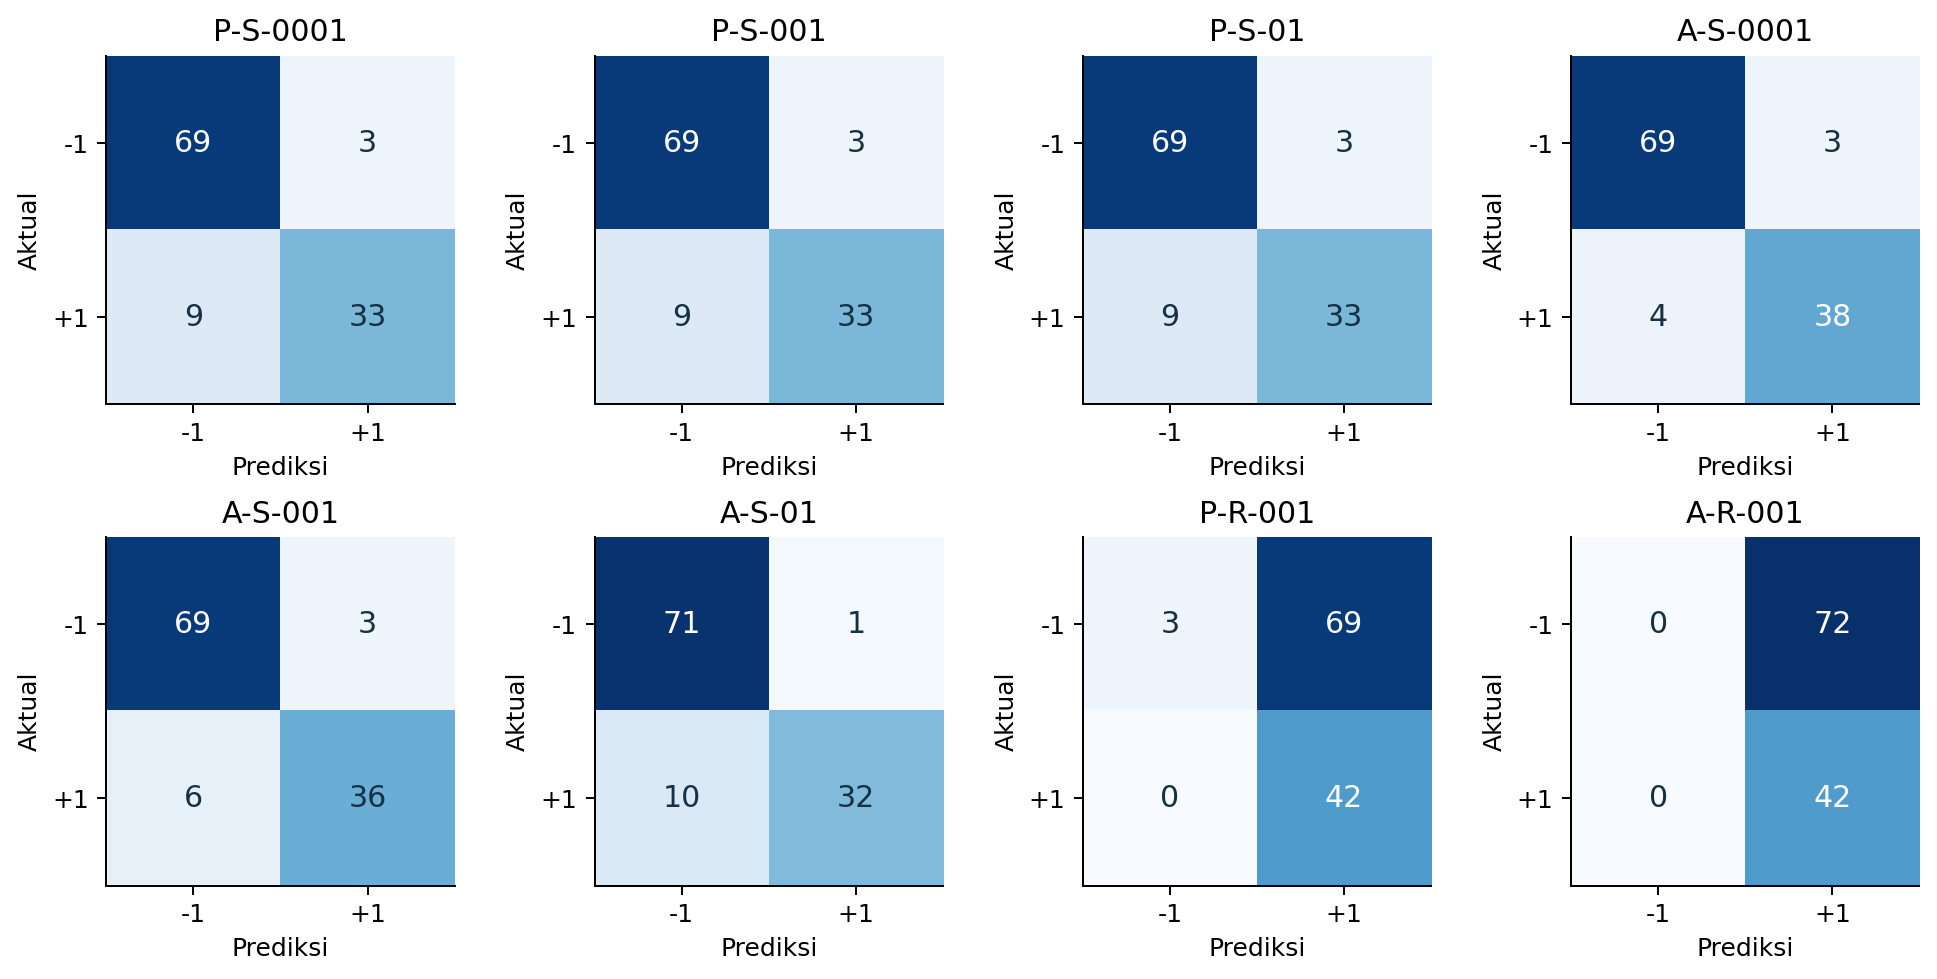

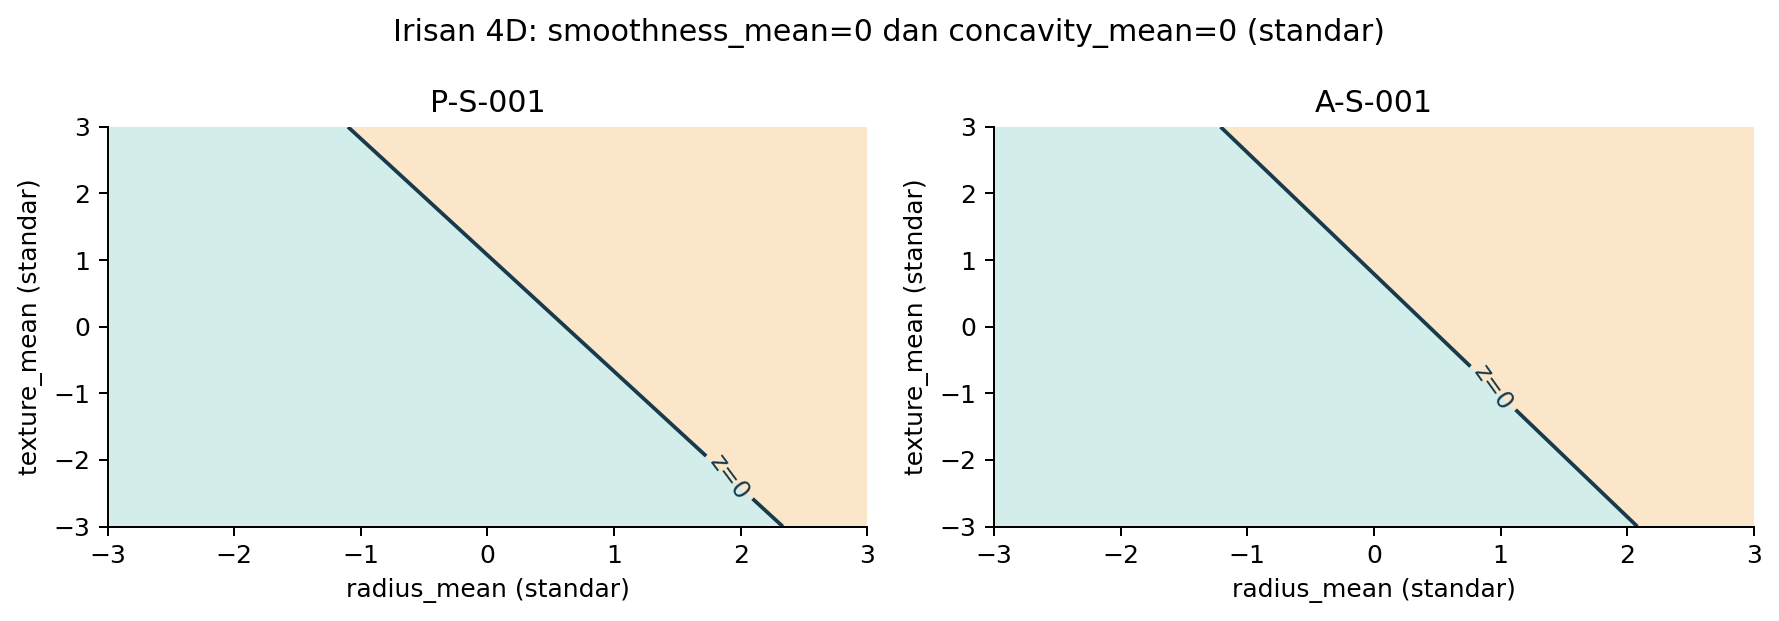

In [32]:
display(tables["metrics"][["id", "tn", "fp", "fn", "tp", "test_precision", "test_recall", "test_f1", "test_balanced_accuracy"]])
display(tables["weights"])
display_png(BASE / "figures/confusion_all.png")
display_png(BASE / "figures/boundary_slice.png")


Confusion matrix memakai baris aktual dan kolom prediksi, keduanya urutan `[-1,+1]`, sehingga `[[TN,FP],[FN,TP]]`. Kelas positif M. Gambar batas keputusan adalah **irisan hiperbidang empat fitur**, dengan smoothness dan concavity ditahan pada rerata train (nol setelah standardisasi), bukan model dua fitur atau proyeksi titik semua sampel. Karena itu titik sampel asli tidak ditempelkan pada irisan seolah semua fitur lainnya nol.

## 13. Verifikasi numerik dan konsistensi

In [34]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

BASE = Path("/content")
hasil = BASE / "results"

wajib = [
    "metrics.csv", "history.csv", "weights.csv",
    "predictions_test.csv", "checkpoints.csv", "manual.json"
]
belum_ada = [nama for nama in wajib if not (hasil / nama).is_file()]
if belum_ada:
    raise FileNotFoundError(
        f"Hasil eksperimen belum lengkap: {belum_ada}. "
        "Jalankan sel eksperimen terlebih dahulu."
    )

# Periksa pembaruan Perceptron pada contoh kecil
X_contoh = np.array([[1., 2.], [-1., 1.]])
y_contoh = np.array([-1, 1])
p = PerceptronNumPy(eta=0.1, epochs=1).fit(X_contoh, y_contoh)
np.testing.assert_allclose(p.w_, [-0.4, -0.2])
np.testing.assert_allclose(p.b_, 0.0)
assert p.history_[0]["updates"] == 2

# Periksa dua pembaruan batch ADALINE
a = AdalineNumPy(eta=0.1, epochs=2).fit(X_contoh, y_contoh)
np.testing.assert_allclose(a.manual_trace_[0]["w_after"], [-0.1, -0.05])
np.testing.assert_allclose(a.w_, [-0.1875, -0.0825])
np.testing.assert_allclose(a.b_, 0.0075)

# Periksa data dan standardisasi berdasarkan data latih
df, tr, te, arrays, yt, ye, scaler = prepare_data(BASE)
np.testing.assert_allclose(arrays[True][0].mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(
    scaler.mean_, df.iloc[tr][FEATURES].mean().to_numpy()
)
np.testing.assert_allclose(
    scaler.scale_, df.iloc[tr][FEATURES].std(ddof=0).to_numpy()
)
assert len(set(tr) & set(te)) == 0

# Periksa jumlah eksperimen, epoch, dan checkpoint
metrik = pd.read_csv(hasil / "metrics.csv")
riwayat = pd.read_csv(hasil / "history.csv")
bobot = pd.read_csv(hasil / "weights.csv").set_index("config")
prediksi = pd.read_csv(hasil / "predictions_test.csv")
checkpoint = pd.read_csv(hasil / "checkpoints.csv")

assert len(metrik) == 8
assert len(riwayat) == 8 * 50
assert len(prediksi) == 8 * len(te)
assert len(checkpoint) == 8 * 3
assert set(checkpoint["epoch"]) == {10, 30, 50}

# Hitung ulang prediksi dan akurasi uji dari bobot yang tersimpan
for baris in metrik.to_dict("records"):
    kode = baris["id"]
    bagian = prediksi[prediksi["config"] == kode]
    X_latih, X_uji = arrays[bool(baris["standardized"])]
    w = bobot.loc[kode, FEATURES].to_numpy(dtype=float)
    b = float(bobot.loc[kode, "bias"])

    prediksi_ulang = np.where(X_uji @ w + b >= 0, 1, -1)
    np.testing.assert_array_equal(
        bagian["prediction"].to_numpy(), prediksi_ulang
    )
    np.testing.assert_allclose(
        baris["test_accuracy"],
        np.mean(prediksi_ulang == bagian["actual"].to_numpy())
    )
    assert int(baris["completed_epochs"]) == 50

    if baris["model"] == "ADALINE":
        np.testing.assert_allclose(
            baris["final_MSE"], 2 * baris["final_J"]
        )

print("VERIFIKASI BERHASIL")
print("8 konfigurasi × 50 epoch, split data, standardisasi,")
print("pembaruan model, prediksi, akurasi, dan MSE = 2J sesuai.")

VERIFIKASI BERHASIL
8 konfigurasi × 50 epoch, split data, standardisasi,
pembaruan model, prediksi, akurasi, dan MSE = 2J sesuai.


## 14. Kesimpulan

Implementasi NumPy kedua model, delapan pelatihan 50 epoch, serta pemeriksaan numerik telah selesai. Pada rancangan ini Perceptron standar menghasilkan akurasi uji 89.47% untuk tiga eta, sedangkan ADALINE standar menghasilkan 93.86%, 92.11%, dan 90.35%. Standardisasi menjaga ADALINE stabil pada eta yang diuji. Penurunan J tidak menjamin kenaikan akurasi kelas. Tidak dilakukan seleksi model berdasarkan data uji.

**Bantuan AI:** ChatGPT membantu draf kode, analisis dan dokumen. Angka berasal dari eksekusi. Setiap anggota perlu Run All, memeriksa penjelasan, dan mencatat kontribusi nyata. Nomor kelompok, anggota final, repository publik dan hash commit masih perlu dilengkapi. Konfirmasi konsultasi penggantian berasal dari pengguna.

## Daftar pustaka

1. UCI Machine Learning. Breast Cancer Wisconsin (Diagnostic) Data Set. Kaggle. https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data. Lisensi pada metadata Kaggle: CC BY-NC-SA 4.0.

2. Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1993). Breast Cancer Wisconsin (Diagnostic) [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B. Lisensi sumber asli: CC BY 4.0.

3. Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. IRE WESCON Convention Record, Part 4, 96-104. https://isl.stanford.edu/~widrow/papers/c1960adaptiveswitching.pdf. Artikel fundamental asli ADALINE.

4. Raschka, S. (2015, 24 Maret). Single-Layer Neural Networks and Gradient Descent. https://sebastianraschka.com/Articles/2015_singlelayer_neurons.html. Tutorial dan kode pendukung.

5. Raschka, S. (tanpa tahun). Adaline: Adaptive Linear Neuron Classifier. Dokumentasi mlxtend. https://rasbt.github.io/mlxtend/user_guide/classifier/Adaline/.

6. scikit-learn developers. StandardScaler; train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html dan https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html. Versi eksekusi 1.8.0.

7. Panduan internal mata kuliah (2026). Tugas Besar 1: Analisis dan Implementasi Klasifikasi Data Menggunakan Perceptron dan ADALINE. IT6053, FTI UKDW. Sumber ketentuan tugas yang diberikan pengguna.

Sumber daring diakses 12 Oktober 2026. Rujukan fundamental asli tidak diperlakukan sebagai bukti klinis terkini.